# Regresión Logística — Clasificador

**Repositorio:** `autodidact/classification/logistic_regression/`

---

## 1. Idea General e Intuición

A pesar del nombre, la **Regresión Logística** es un modelo de **clasificación**, no de regresión. Modela la **probabilidad** de pertenencia a una clase usando la función sigmoide para "aplastar" una combinación lineal de features al rango $[0, 1]$.

**Intuición:** Imagina una recta que separa dos clases. La regresión logística aprende esa frontera lineal y además asigna probabilidades suaves a cada lado de la frontera, en lugar de simplemente etiquetar.

## 2. Fundamento Matemático

### 2.1 Función Sigmoide

$$\sigma(z) = \frac{1}{1 + e^{-z}}, \quad z \in \mathbb{R} \Rightarrow \sigma(z) \in (0, 1)$$

### 2.2 Modelo Lineal + Sigmoide

Para clasificación binaria con features $\mathbf{x} \in \mathbb{R}^d$ y parámetros $\mathbf{w}, b$:

$$\hat{p} = P(y=1 \mid \mathbf{x}) = \sigma(\mathbf{w}^\top \mathbf{x} + b) = \frac{1}{1 + e^{-(\mathbf{w}^\top \mathbf{x} + b)}}$$

Regla de decisión con umbral $\theta = 0.5$:

$$\hat{y} = \begin{cases} 1 & \text{si } \hat{p} \geq 0.5 \\ 0 & \text{si } \hat{p} < 0.5 \end{cases}$$

### 2.3 Log-Odds (Logit)

La transformación logit muestra que el modelo es **lineal en los log-odds**:

$$\log\frac{\hat{p}}{1-\hat{p}} = \mathbf{w}^\top \mathbf{x} + b$$

### 2.4 Función de Pérdida — Binary Cross-Entropy

$$\mathcal{L}(\mathbf{w}) = -\frac{1}{n}\sum_{i=1}^{n}\left[y_i \log\hat{p}_i + (1-y_i)\log(1-\hat{p}_i)\right]$$

No tiene solución analítica cerrada → se optimiza con **Descenso de Gradiente** o **L-BFGS**.

### 2.5 Regularización

Para evitar sobreajuste se añade una penalización a los pesos:

**Ridge (L2):**
$$\mathcal{L}_\text{reg} = \mathcal{L} + \frac{1}{2C}\|\mathbf{w}\|_2^2$$

**Lasso (L1):**
$$\mathcal{L}_\text{reg} = \mathcal{L} + \frac{1}{C}\|\mathbf{w}\|_1$$

**Elastic Net:**
$$\mathcal{L}_\text{reg} = \mathcal{L} + \frac{1}{C}\left[\frac{1-\rho}{2}\|\mathbf{w}\|_2^2 + \rho\|\mathbf{w}\|_1\right]$$

> **Nota:** En scikit-learn, `C` es la **inversa** de la intensidad de regularización. $C$ grande → poca regularización.

### 2.6 Clasificación Multiclase

**One-vs-Rest (OvR):** Un clasificador binario por clase.

**Softmax (Multinomial):** Generalización directa:
$$P(y=k \mid \mathbf{x}) = \frac{e^{\mathbf{w}_k^\top \mathbf{x}}}{\sum_{j=1}^K e^{\mathbf{w}_j^\top \mathbf{x}}}$$

## 3. ¿Cuándo Usarlo y Cuándo NO?

### ✅ Úsalo cuando:
- Necesitas **probabilidades bien calibradas** de salida.
- La relación feature-target es **aproximadamente lineal** en el espacio logit.
- El dataset es **muy grande** (converge rápido con SGD).
- Necesitas **interpretabilidad** de los coeficientes (dirección e importancia).
- Como **baseline lineal** antes de modelos más complejos.

### ❌ NO lo uses cuando:
- Las clases **no son linealmente separables** (usar SVM con kernel, Random Forest).
- Las features tienen **interacciones complejas** no modeladas.
- El dataset tiene **muchos outliers** (los coeficientes se distorsionan).

## 4. Métricas de Evaluación

| Métrica | Fórmula | Cuándo usarla |
|---|---|---|
| **Accuracy** | $\frac{TP+TN}{N}$ | Clases balanceadas |
| **ROC-AUC** | Área bajo ROC | Evaluar ranking probabilístico |
| **Log-loss** | $-\frac{1}{n}\sum y\log\hat{p}$ | Calidad de las probabilidades |
| **F1-Score** | $\frac{2PR}{P+R}$ | Clases desbalanceadas |

**Interpretación de coeficientes (odds ratio):**
$$\text{Odds Ratio}_j = e^{w_j}$$
Un aumento de 1 unidad en $x_j$ multiplica los odds por $e^{w_j}$.

## 5. Problemas y Casos Raros

### 5.1 Separabilidad Perfecta
Si las clases son perfectamente separables linealmente, los coeficientes divergen a $\pm\infty$.
**Solución:** Regularización L2 (siempre recomendada).

### 5.2 Multicolinealidad
Features altamente correlacionadas hacen los coeficientes inestables.
**Solución:** L2 regularización o eliminar features correlacionadas.

### 5.3 Features No Escaladas
El optimizador (especialmente L-BFGS) converge más lento sin escalado.
**Solución:** Siempre usar `StandardScaler`.

### 5.4 Clases Desbalanceadas
El umbral default 0.5 no es óptimo.
**Solución:** `class_weight='balanced'` o ajustar el umbral de decisión con la curva ROC.

### 5.5 Convergencia
Con `solver='lbfgs'` y datasets grandes puede no converger con el default `max_iter=100`.
**Solución:** Aumentar `max_iter` o usar `solver='saga'` para datasets grandes.

## 6. Mejora de Resultados

| Parámetro | Efecto |
|---|---|
| `C` | Inversa de regularización: ↑C → menos regularización |
| `penalty` | `'l1'`, `'l2'`, `'elasticnet'`, `'none'` |
| `solver` | `'lbfgs'` (default), `'saga'` (L1/ElasticNet/grandes datasets) |
| `max_iter` | Aumentar si hay warnings de convergencia |
| `class_weight` | `'balanced'` para clases desbalanceadas |
| `multi_class` | `'ovr'` o `'multinomial'` |

**Pipeline recomendado:** `StandardScaler → LogisticRegression`

In [1]:
# =============================================================================
# SETUP
# =============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay,
    log_loss, PrecisionRecallDisplay
)

import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
SEED = 42
print('✅ Librerías cargadas.')

✅ Librerías cargadas.


---
## 7. Clasificación Binaria — Breast Cancer

In [2]:
# =============================================================================
# CARGA Y SPLIT
# =============================================================================
bc = load_breast_cancer(as_frame=True)
X, y = bc.data, bc.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print(f'Train: {X_train.shape} | Test: {X_test.shape}')
print(f'Clases: {bc.target_names}')

Train: (455, 30) | Test: (114, 30)
Clases: ['malignant' 'benign']


In [3]:
# =============================================================================
# PIPELINE: StandardScaler + LogisticRegression
# El escalado es OBLIGATORIO para la convergencia correcta del optimizador.
# =============================================================================
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(penalty='l2', C=1.0, solver='lbfgs',
                               max_iter=1000, random_state=SEED))
])
pipe.fit(X_train, y_train)
y_pred  = pipe.predict(X_test)
y_proba = pipe.predict_proba(X_test)[:, 1]

print(f'Accuracy : {accuracy_score(y_test, y_pred):.4f}')
print(f'ROC-AUC  : {roc_auc_score(y_test, y_proba):.4f}')
print(f'Log-loss : {log_loss(y_test, y_proba):.4f}')
print()
print(classification_report(y_test, y_pred, target_names=bc.target_names))

Accuracy : 0.9825
ROC-AUC  : 0.9954
Log-loss : 0.0777

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



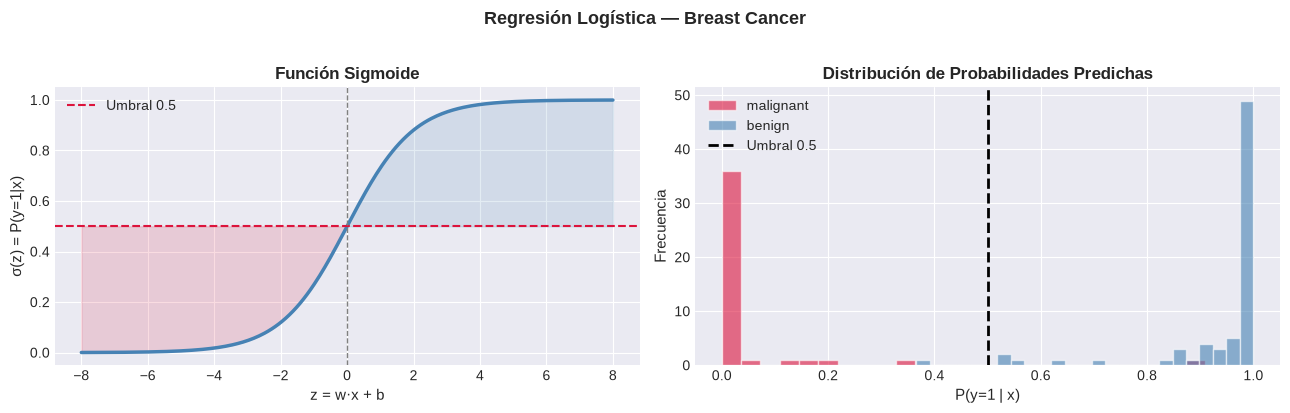

In [4]:
# =============================================================================
# VISUALIZACIÓN 1: Función Sigmoide + Frontera de Decisión 1D
# Ilustra cómo el modelo transforma la combinación lineal en probabilidad
# =============================================================================
z = np.linspace(-8, 8, 300)
sigmoid = 1 / (1 + np.exp(-z))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Sigmoide
axes[0].plot(z, sigmoid, color='steelblue', lw=2.5)
axes[0].axhline(0.5, color='crimson', linestyle='--', lw=1.5, label='Umbral 0.5')
axes[0].axvline(0.0, color='gray',    linestyle='--', lw=1)
axes[0].fill_between(z, sigmoid, 0.5, where=(z >= 0), alpha=0.15, color='steelblue')
axes[0].fill_between(z, sigmoid, 0.5, where=(z <= 0), alpha=0.15, color='crimson')
axes[0].set_xlabel('z = w·x + b', fontsize=11)
axes[0].set_ylabel('σ(z) = P(y=1|x)', fontsize=11)
axes[0].set_title('Función Sigmoide', fontsize=12, fontweight='bold')
axes[0].legend(); axes[0].set_ylim(-0.05, 1.05)

# Probabilidades predichas por clase
proba_df = pd.DataFrame({'prob': y_proba, 'clase': y_test.map({0: bc.target_names[0],
                                                                1: bc.target_names[1]})})
for cls, color in zip(bc.target_names, ['crimson', 'steelblue']):
    subset = proba_df[proba_df['clase'] == cls]['prob']
    axes[1].hist(subset, bins=25, alpha=0.6, color=color, label=cls, edgecolor='white')
axes[1].axvline(0.5, color='black', linestyle='--', lw=2, label='Umbral 0.5')
axes[1].set_xlabel('P(y=1 | x)', fontsize=11)
axes[1].set_ylabel('Frecuencia', fontsize=11)
axes[1].set_title('Distribución de Probabilidades Predichas', fontsize=12, fontweight='bold')
axes[1].legend()

plt.suptitle('Regresión Logística — Breast Cancer', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

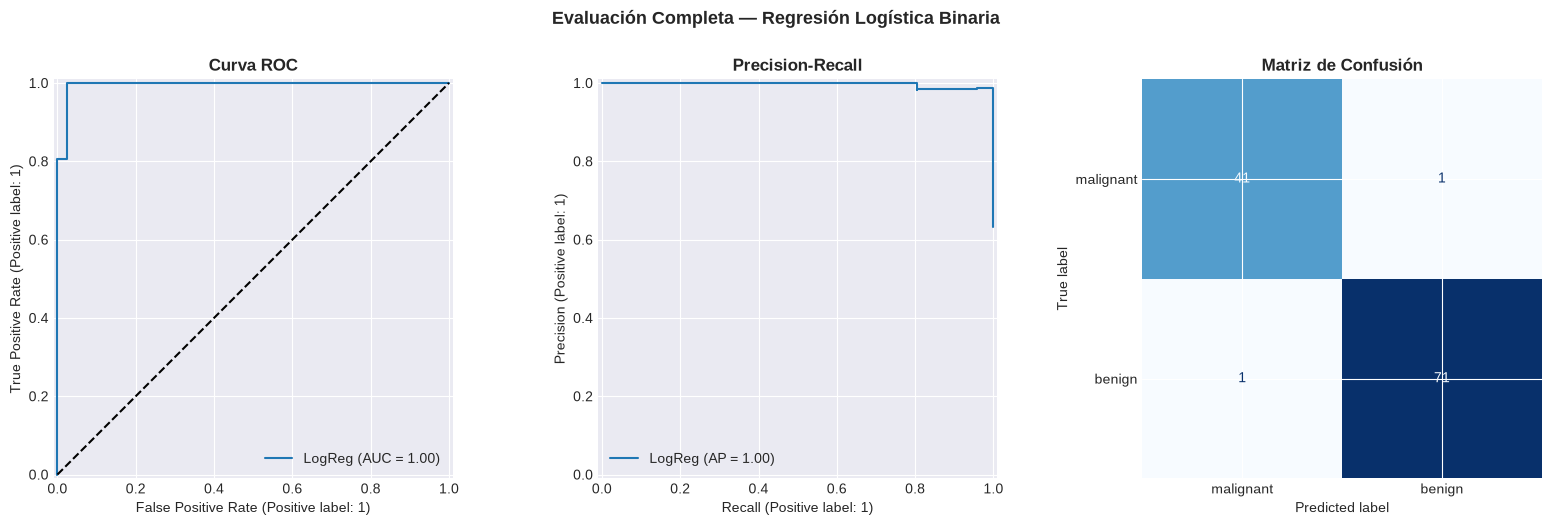

In [5]:
# =============================================================================
# VISUALIZACIÓN 2: ROC + Precision-Recall + Matriz de Confusión
# =============================================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

RocCurveDisplay.from_estimator(pipe, X_test, y_test, ax=axes[0], name='LogReg')
axes[0].plot([0,1],[0,1],'k--'); axes[0].set_title('Curva ROC', fontweight='bold')

PrecisionRecallDisplay.from_estimator(pipe, X_test, y_test, ax=axes[1], name='LogReg')
axes[1].set_title('Precision-Recall', fontweight='bold')

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=bc.target_names).plot(
    ax=axes[2], colorbar=False, cmap='Blues')
axes[2].set_title('Matriz de Confusión', fontweight='bold')

plt.suptitle('Evaluación Completa — Regresión Logística Binaria',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Top 10 features más influyentes:
             Feature  Coeficiente  Odds Ratio
       worst texture    -1.255088    0.285051
        radius error    -1.082965    0.338590
worst concave points    -0.953686    0.385318
          worst area    -0.947756    0.387610
        worst radius    -0.947616    0.387664
      worst symmetry    -0.939181    0.390948
          area error    -0.929104    0.394907
     worst concavity    -0.823151    0.439046
     worst perimeter    -0.763220    0.466163
    worst smoothness    -0.746625    0.473964


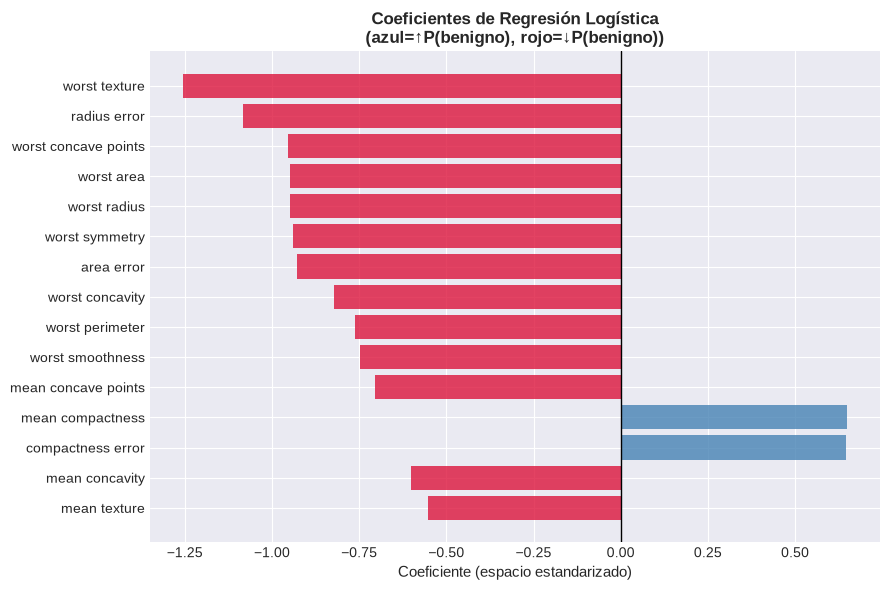

In [6]:
# =============================================================================
# COEFICIENTES E INTERPRETACIÓN (Odds Ratios)
# w_j > 0 → esa feature aumenta la probabilidad de la clase positiva
# e^{w_j} = odds ratio: cuánto multiplica los odds un aumento de 1σ en x_j
# =============================================================================
lr_model = pipe.named_steps['lr']
coefs    = lr_model.coef_[0]
odds     = np.exp(coefs)

coef_df = pd.DataFrame({
    'Feature':     bc.feature_names,
    'Coeficiente': coefs,
    'Odds Ratio':  odds
}).sort_values('Coeficiente', key=abs, ascending=False)

print('Top 10 features más influyentes:')
print(coef_df.head(10).to_string(index=False))

# Gráfico de coeficientes
top15 = coef_df.head(15).set_index('Feature')
colors = ['steelblue' if c > 0 else 'crimson' for c in top15['Coeficiente']]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top15.index[::-1], top15['Coeficiente'].values[::-1],
        color=colors[::-1], alpha=0.8)
ax.axvline(0, color='black', lw=1)
ax.set_xlabel('Coeficiente (espacio estandarizado)', fontsize=11)
ax.set_title('Coeficientes de Regresión Logística\n(azul=↑P(benigno), rojo=↓P(benigno))',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 8. Efecto de la Regularización (C)

Mejor C: 0.1194 | ROC-AUC: 0.9938


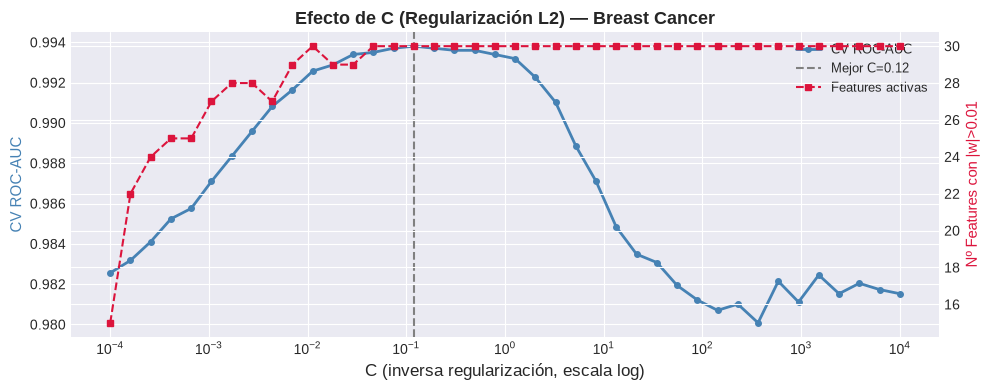

In [7]:
# =============================================================================
# CURVA DE REGULARIZACIÓN: C vs Accuracy + sparsity de coeficientes
# C pequeño = fuerte regularización → coeficientes hacia 0
# C grande  = poca regularización  → riesgo de sobreajuste
# =============================================================================
C_values = np.logspace(-4, 4, 40)
cv_scores, n_nonzero = [], []

for C in C_values:
    pipe_c = Pipeline([
        ('scaler', StandardScaler()),
        ('lr', LogisticRegression(C=C, penalty='l2', solver='lbfgs',
                                   max_iter=1000, random_state=SEED))
    ])
    sc = cross_val_score(pipe_c, X_train, y_train, cv=5, scoring='roc_auc')
    cv_scores.append(sc.mean())
    pipe_c.fit(X_train, y_train)
    n_nonzero.append(np.sum(np.abs(pipe_c.named_steps['lr'].coef_[0]) > 0.01))

best_C = C_values[int(np.argmax(cv_scores))]
print(f'Mejor C: {best_C:.4f} | ROC-AUC: {max(cv_scores):.4f}')

fig, ax1 = plt.subplots(figsize=(10, 4))
ax2 = ax1.twinx()
ax1.semilogx(C_values, cv_scores, 'o-', color='steelblue', lw=2, ms=4, label='CV ROC-AUC')
ax1.axvline(best_C, color='gray', linestyle='--', label=f'Mejor C={best_C:.2f}')
ax2.semilogx(C_values, n_nonzero, 's--', color='crimson', lw=1.5, ms=4, label='Features activas')
ax1.set_xlabel('C (inversa regularización, escala log)', fontsize=12)
ax1.set_ylabel('CV ROC-AUC', color='steelblue', fontsize=11)
ax2.set_ylabel('Nº Features con |w|>0.01', color='crimson', fontsize=11)
ax1.set_title('Efecto de C (Regularización L2) — Breast Cancer', fontsize=13, fontweight='bold')
lines1, lab1 = ax1.get_legend_handles_labels()
lines2, lab2 = ax2.get_legend_handles_labels()
ax1.legend(lines1+lines2, lab1+lab2, fontsize=9)
plt.tight_layout()
plt.show()

---
## 9. Ajuste del Umbral de Decisión

Umbral de Youden óptimo: 0.3659
  TPR (Recall): 1.0000
  FPR         : 0.0238

Accuracy (umbral 0.5)   : 0.9825
Accuracy (umbral Youden): 0.9912


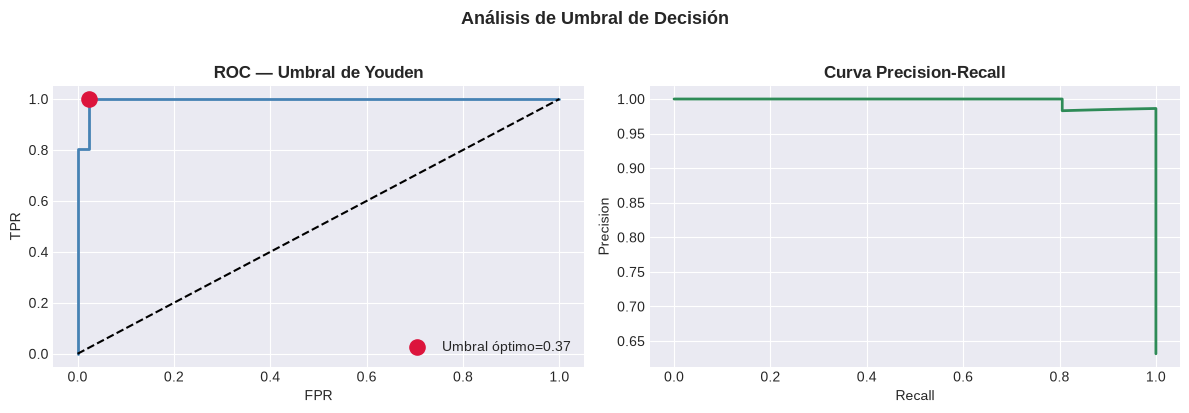

In [8]:
# =============================================================================
# AJUSTE DE UMBRAL: La curva ROC permite elegir el umbral óptimo
# para diferentes trade-offs Precision/Recall.
# Útil cuando el coste de FP y FN no es simétrico.
# =============================================================================
from sklearn.metrics import roc_curve, precision_recall_curve

fpr, tpr, thresholds_roc = roc_curve(y_test, y_proba)
prec, rec, thresholds_pr = precision_recall_curve(y_test, y_proba)

# Umbral óptimo según índice de Youden (maximiza TPR - FPR)
youden_idx = np.argmax(tpr - fpr)
best_thresh = thresholds_roc[youden_idx]
print(f'Umbral de Youden óptimo: {best_thresh:.4f}')
print(f'  TPR (Recall): {tpr[youden_idx]:.4f}')
print(f'  FPR         : {fpr[youden_idx]:.4f}')

# Predicción con umbral ajustado
y_pred_adj = (y_proba >= best_thresh).astype(int)
print(f'\nAccuracy (umbral 0.5)   : {accuracy_score(y_test, y_pred):.4f}')
print(f'Accuracy (umbral Youden): {accuracy_score(y_test, y_pred_adj):.4f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(fpr, tpr, color='steelblue', lw=2)
axes[0].scatter(fpr[youden_idx], tpr[youden_idx], s=120, color='crimson', zorder=5,
                label=f'Umbral óptimo={best_thresh:.2f}')
axes[0].plot([0,1],[0,1],'k--'); axes[0].legend()
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
axes[0].set_title('ROC — Umbral de Youden', fontweight='bold')

axes[1].plot(rec, prec, color='seagreen', lw=2)
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Curva Precision-Recall', fontweight='bold')

plt.suptitle('Análisis de Umbral de Decisión', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 10. Clasificación Multiclase — Iris (Softmax)

In [9]:
# =============================================================================
# MULTICLASE con multi_class='multinomial' (Softmax)
# =============================================================================
from matplotlib.colors import ListedColormap
from sklearn.decomposition import PCA

iris = load_iris(as_frame=True)
X_ir, y_ir = iris.data, iris.target

X_tr_ir, X_te_ir, y_tr_ir, y_te_ir = train_test_split(
    X_ir, y_ir, test_size=0.2, random_state=SEED, stratify=y_ir
)

pipe_multi = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(multi_class='multinomial', solver='lbfgs',
                               C=1.0, max_iter=1000, random_state=SEED))
])
pipe_multi.fit(X_tr_ir, y_tr_ir)
y_pred_ir = pipe_multi.predict(X_te_ir)

print(f'Accuracy multiclase (Softmax): {accuracy_score(y_te_ir, y_pred_ir):.4f}')
print(classification_report(y_te_ir, y_pred_ir, target_names=iris.target_names))

# Frontera 2D via PCA
scaler_pca = StandardScaler()
pca = PCA(n_components=2, random_state=SEED)
X_tr_2d = pca.fit_transform(scaler_pca.fit_transform(X_tr_ir))
X_te_2d = pca.transform(scaler_pca.transform(X_te_ir))

lr_2d = LogisticRegression(multi_class='multinomial', solver='lbfgs', C=1.0,
                            max_iter=1000, random_state=SEED)
lr_2d.fit(X_tr_2d, y_tr_ir)

h = 0.05
xx, yy = np.meshgrid(np.arange(X_tr_2d[:,0].min()-1, X_tr_2d[:,0].max()+1, h),
                     np.arange(X_tr_2d[:,1].min()-1, X_tr_2d[:,1].max()+1, h))
Z = lr_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

cmap_bg  = ListedColormap(['#FFAAAA','#AAFFAA','#AAAAFF'])
cmap_pts = ListedColormap(['#CC0000','#00AA00','#0000CC'])

fig, ax = plt.subplots(figsize=(8, 6))
ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bg)
ax.scatter(X_tr_2d[:,0], X_tr_2d[:,1], c=y_tr_ir, cmap=cmap_pts,
           edgecolors='k', s=50, label='Train')
ax.scatter(X_te_2d[:,0], X_te_2d[:,1], c=y_te_ir, cmap=cmap_pts,
           edgecolors='white', s=80, marker='^', label='Test')
ax.set_title('Frontera de Decisión — Softmax Multiclase (Iris, PCA 2D)',
             fontsize=12, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

TypeError: LogisticRegression.__init__() got an unexpected keyword argument 'multi_class'

In [ ]:
# =============================================================================
# HYPERPARAMETER TUNING: C + penalty con GridSearchCV
# =============================================================================
param_grid = {
    'lr__C':       [0.001, 0.01, 0.1, 1, 10, 100],
    'lr__penalty': ['l1', 'l2'],
    'lr__solver':  ['saga']   # saga soporta L1 y L2
}

pipe_gs = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(max_iter=2000, random_state=SEED))
])

grid = GridSearchCV(pipe_gs, param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train, y_train)

print(f'Mejores parámetros: {grid.best_params_}')
print(f'Mejor ROC-AUC (CV): {grid.best_score_:.4f}')
best_lr = grid.best_estimator_
y_pred_gs = best_lr.predict(X_test)
y_proba_gs = best_lr.predict_proba(X_test)[:,1]
print(f'Test ROC-AUC      : {roc_auc_score(y_test, y_proba_gs):.4f}')

---
## 11. Resumen y Checklist

| Aspecto | Detalle |
|---|---|
| **Tipo** | Clasificador lineal probabilístico |
| **Preprocesamiento** | `StandardScaler` obligatorio |
| **Salida** | Probabilidades calibradas |
| **Regularización** | L1 (sparsity), L2 (default), ElasticNet |
| **Interpretabilidad** | Alta: coeficientes = importancia de features |
| **Limitación** | Solo frontera lineal |

### ✅ Checklist:
- [ ] ¿Escalé las features con `StandardScaler`?
- [ ] ¿Aumenté `max_iter` si hay warnings de convergencia?
- [ ] ¿Usé `class_weight='balanced'` si hay desbalanceo?
- [ ] ¿Evalué la calibración con la curva de calibración?
- [ ] ¿Ajusté el umbral de decisión con la curva ROC?
- [ ] ¿Interpreté los coeficientes como odds ratios?

---
*Próximo notebook: LDA / QDA*